In [1]:
import pandas as pd

reviews = pd.read_csv("../data/raw/reviews.csv")

print("Dataset shape:", reviews.shape)
print("\nColumn names:")
print(reviews.columns.tolist())

print("\nFirst five rows:")
display(reviews.head())

Dataset shape: (3000, 6)

Column names:
['review_id', 'order_id', 'customer_id', 'review_text', 'sentiment', 'review_date']

First five rows:


,review_id,order_id,customer_id,review_text,sentiment,review_date
0,1,1,258,Amazing experience,Positive,2025-09-17 12:00:00
1,2,2,180,Fresh food delivered on time,Positive,2025-09-27 15:00:00
2,3,3,487,Loved the food and service,Positive,2025-04-30 07:00:00
3,4,4,373,Order was incorrect,Negative,2025-02-19 01:00:00
4,5,5,172,Poor packaging and bad service,Negative,2025-07-18 08:00:00


In [2]:
# Check missing values
print("Missing values:")
print(reviews.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", reviews.duplicated().sum())

# Check duplicate review IDs
print("Duplicate review IDs:", reviews["review_id"].duplicated().sum())

# Check sentiment distribution
print("\nSentiment distribution:")
print(reviews["sentiment"].value_counts(dropna=False))

# Check unique sentiment labels
print("\nUnique sentiment labels:")
print(reviews["sentiment"].unique())

# Check empty or whitespace-only reviews
empty_reviews = (
    reviews["review_text"]
    .astype("string")
    .str.strip()
    .eq("")
    .fillna(False)
)

print("\nEmpty review texts:", empty_reviews.sum())

Missing values:
review_id      0
order_id       0
customer_id    0
review_text    0
sentiment      0
review_date    0
dtype: int64

Duplicate rows: 0
Duplicate review IDs: 0

Sentiment distribution:
sentiment
Positive    1766
Negative     779
Neutral      455
Name: count, dtype: int64

Unique sentiment labels:
['Positive' 'Negative' 'Neutral']

Empty review texts: 0


In [3]:
# Create a copy so the original dataset remains unchanged
reviews_cleaned = reviews.copy()

# Remove rows missing review text or sentiment
reviews_cleaned = reviews_cleaned.dropna(
    subset=["review_text", "sentiment"]
).copy()

# Remove reviews containing only whitespace
reviews_cleaned = reviews_cleaned[
    reviews_cleaned["review_text"].astype(str).str.strip().ne("")
].copy()

# Standardize review text and sentiment labels
reviews_cleaned["review_text"] = (
    reviews_cleaned["review_text"].astype(str).str.strip()
)

reviews_cleaned["sentiment"] = (
    reviews_cleaned["sentiment"].astype(str).str.strip().str.title()
)

# Remove duplicate review IDs, keeping the first occurrence
reviews_cleaned = reviews_cleaned.drop_duplicates(
    subset=["review_id"],
    keep="first"
).copy()

print("Original rows:", len(reviews))
print("Cleaned rows:", len(reviews_cleaned))

print("\nCleaned sentiment distribution:")
print(reviews_cleaned["sentiment"].value_counts())

display(reviews_cleaned.head())

Original rows: 3000
Cleaned rows: 3000

Cleaned sentiment distribution:
sentiment
Positive    1766
Negative     779
Neutral      455
Name: count, dtype: int64


,review_id,order_id,customer_id,review_text,sentiment,review_date
0,1,1,258,Amazing experience,Positive,2025-09-17 12:00:00
1,2,2,180,Fresh food delivered on time,Positive,2025-09-27 15:00:00
2,3,3,487,Loved the food and service,Positive,2025-04-30 07:00:00
3,4,4,373,Order was incorrect,Negative,2025-02-19 01:00:00
4,5,5,172,Poor packaging and bad service,Negative,2025-07-18 08:00:00


In [4]:
import os

os.makedirs("../data/processed", exist_ok=True)

reviews_cleaned.to_csv(
    "../data/processed/cleaned_reviews.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [5]:
%pip install nltk scikit-learn vaderSentiment

Note: you may need to restart the kernel to use updated packages.


In [6]:
import re
import string
import nltk
import pandas as pd

from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /home/nineleaps/nltk_data...


True

In [8]:
# Load the cleaned dataset
reviews_cleaned = pd.read_csv("../data/processed/cleaned_reviews.csv")

# Initialize stop words and lemmatizer
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# Preserve negation words because they affect sentiment
stop_words = stop_words - {"no", "nor", "not"}

def preprocess_review(text):
    # Convert text to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", "", text)

    # Remove punctuation and special characters, keeping letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenize the text into words
    tokens = wordpunct_tokenize(text)

    # Remove stop words and very short tokens
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    # Lemmatize words
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Return the processed words as a single string
    return " ".join(tokens)

# Apply preprocessing
reviews_cleaned["processed_review"] = (
    reviews_cleaned["review_text"].apply(preprocess_review)
)

# Display original and processed reviews
display(
    reviews_cleaned[
        ["review_text", "processed_review", "sentiment"]
    ].head(10)
)

,review_text,processed_review,sentiment
0,Amazing experience,amazing experience,Positive
1,Fresh food delivered on time,fresh food delivered time,Positive
2,Loved the food and service,loved food service,Positive
3,Order was incorrect,order incorrect,Negative
4,Poor packaging and bad service,poor packaging bad service,Negative
5,Excellent taste and good packaging,excellent taste good packaging,Positive
6,Great food and quick delivery,great food quick delivery,Positive
7,Order was incorrect,order incorrect,Negative
8,Excellent taste and good packaging,excellent taste good packaging,Positive
9,Fresh food delivered on time,fresh food delivered time,Positive


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize the TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2)
)

# Convert processed reviews into numerical features
X_tfidf = tfidf_vectorizer.fit_transform(
    reviews_cleaned["processed_review"]
)

# Display matrix information
print("Number of reviews:", X_tfidf.shape[0])
print("Number of TF-IDF features:", X_tfidf.shape[1])
print("TF-IDF matrix shape:", X_tfidf.shape)

# Display the first 5 feature names
print("\nSample TF-IDF features:")
print(tfidf_vectorizer.get_feature_names_out()[:5])

Number of reviews: 3000
Number of TF-IDF features: 54
TF-IDF matrix shape: (3000, 54)

Sample TF-IDF features:
['acceptable' 'amazing' 'amazing experience' 'arrived' 'arrived late']


In [10]:
import os
from scipy.sparse import save_npz
import joblib

# Create the processed data directory if needed
os.makedirs("../data/processed", exist_ok=True)

# Save the TF-IDF matrix
save_npz(
    "../data/processed/reviews_tfidf.npz",
    X_tfidf
)

# Save the fitted vectorizer for future use
joblib.dump(
    tfidf_vectorizer,
    "../data/processed/tfidf_vectorizer.pkl"
)

print("TF-IDF matrix saved successfully!")
print("TF-IDF vectorizer saved successfully!")

TF-IDF matrix saved successfully!
TF-IDF vectorizer saved successfully!


In [11]:
from sklearn.model_selection import train_test_split

# Input features: TF-IDF matrix
X = X_tfidf

# Target: sentiment labels
y = reviews_cleaned["sentiment"]

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training reviews:", X_train.shape[0])
print("Testing reviews:", X_test.shape[0])
print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

Training reviews: 2400
Testing reviews: 600
Training features: 54
Testing features: 54


In [12]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# Initialize the models
nb_model = MultinomialNB()
svm_model = LinearSVC(random_state=42)

# Train Naive Bayes
nb_model.fit(X_train, y_train)

# Train SVM
svm_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")
print("SVM model trained successfully!")

Naive Bayes model trained successfully!
SVM model trained successfully!


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import pandas as pd

# Generate predictions
nb_predictions = nb_model.predict(X_test)
svm_predictions = svm_model.predict(X_test)

# Calculate evaluation metrics
results = pd.DataFrame({
    "Model": ["Naive Bayes", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, svm_predictions)
    ],
    "Precision": [
        precision_score(y_test, nb_predictions, average="weighted", zero_division=0),
        precision_score(y_test, svm_predictions, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, nb_predictions, average="weighted", zero_division=0),
        recall_score(y_test, svm_predictions, average="weighted", zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, nb_predictions, average="weighted", zero_division=0),
        f1_score(y_test, svm_predictions, average="weighted", zero_division=0)
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,1.0,1.0,1.0,1.0
1,SVM,1.0,1.0,1.0,1.0


In [14]:
print("NAIVE BAYES CLASSIFICATION REPORT")
print(classification_report(y_test, nb_predictions, zero_division=0))

print("\nSVM CLASSIFICATION REPORT")
print(classification_report(y_test, svm_predictions, zero_division=0))

NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       156
     Neutral       1.00      1.00      1.00        91
    Positive       1.00      1.00      1.00       353

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600


SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       156
     Neutral       1.00      1.00      1.00        91
    Positive       1.00      1.00      1.00       353

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



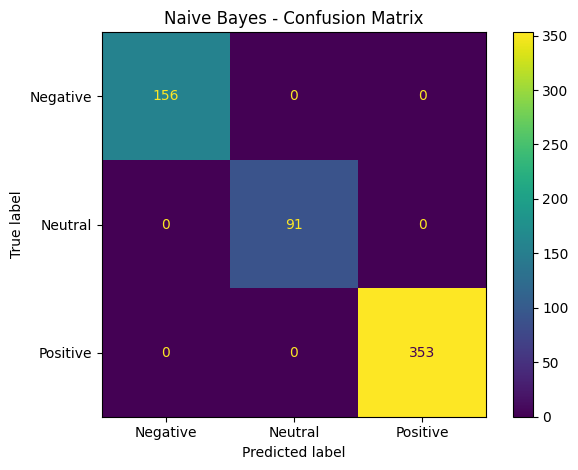

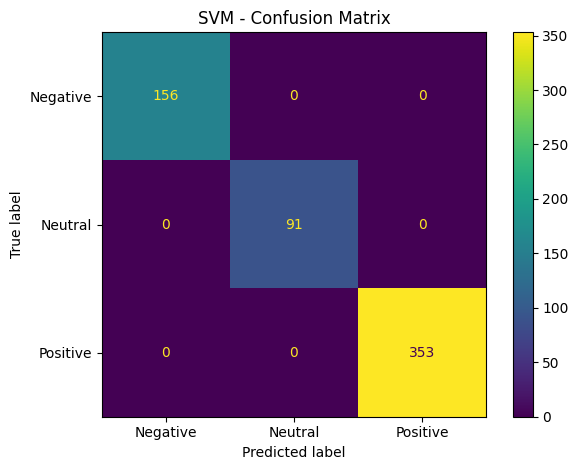

Confusion matrices saved to: /home/nineleaps/Downloads/Uber_Eats_Operational_Intelligence/outputs/visualizations


In [16]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create the output folder
output_dir = os.path.abspath("../outputs/visualizations")
os.makedirs(output_dir, exist_ok=True)

sentiment_labels = ["Negative", "Neutral", "Positive"]

# Plot and save Naive Bayes confusion matrix
nb_cm = confusion_matrix(
    y_test, nb_predictions, labels=sentiment_labels
)

ConfusionMatrixDisplay(
    confusion_matrix=nb_cm,
    display_labels=sentiment_labels
).plot(values_format="d")

plt.title("Naive Bayes - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "naive_bayes_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot and save SVM confusion matrix
svm_cm = confusion_matrix(
    y_test, svm_predictions, labels=sentiment_labels
)

ConfusionMatrixDisplay(
    confusion_matrix=svm_cm,
    display_labels=sentiment_labels
).plot(values_format="d")

plt.title("SVM - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "svm_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Confusion matrices saved to:", output_dir)

In [17]:
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.metrics import accuracy_score, classification_report

# Download the VADER sentiment lexicon
nltk.download("vader_lexicon")

# Initialize VADER
vader = SentimentIntensityAnalyzer()

# Calculate sentiment scores for each review
reviews_cleaned["vader_scores"] = reviews_cleaned["review_text"].apply(
    vader.polarity_scores
)

# Extract the compound score
reviews_cleaned["vader_compound"] = reviews_cleaned["vader_scores"].apply(
    lambda scores: scores["compound"]
)

# Convert compound scores into sentiment labels
def classify_vader(compound_score):
    if compound_score >= 0.05:
        return "Positive"
    elif compound_score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

reviews_cleaned["vader_sentiment"] = reviews_cleaned["vader_compound"].apply(
    classify_vader
)

# Display sample predictions
display(
    reviews_cleaned[
        ["review_text", "sentiment", "vader_compound", "vader_sentiment"]
    ].head(15)
)

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/nineleaps/nltk_data...


,review_text,sentiment,vader_compound,vader_sentiment
0,Amazing experience,Positive,0.5859,Positive
1,Fresh food delivered on time,Positive,0.3182,Positive
2,Loved the food and service,Positive,0.5994,Positive
3,Order was incorrect,Negative,0.0000,Neutral
4,Poor packaging and bad service,Negative,-0.7650,Negative
5,Excellent taste and good packaging,Positive,0.7650,Positive
6,Great food and quick delivery,Positive,0.6249,Positive
7,Order was incorrect,Negative,0.0000,Neutral
8,Excellent taste and good packaging,Positive,0.7650,Positive
9,Fresh food delivered on time,Positive,0.3182,Positive


In [18]:
# Compare VADER predictions against the existing sentiment labels
vader_accuracy = accuracy_score(
    reviews_cleaned["sentiment"],
    reviews_cleaned["vader_sentiment"]
)

print(f"VADER Accuracy: {vader_accuracy:.4f}")
print("\nVADER Classification Report:")
print(
    classification_report(
        reviews_cleaned["sentiment"],
        reviews_cleaned["vader_sentiment"],
        zero_division=0
    )
)

VADER Accuracy: 0.7470

VADER Classification Report:
              precision    recall  f1-score   support

    Negative       0.76      0.38      0.50       779
     Neutral       0.27      0.40      0.32       455
    Positive       0.91      1.00      0.95      1766

    accuracy                           0.75      3000
   macro avg       0.64      0.59      0.59      3000
weighted avg       0.77      0.75      0.74      3000



In [ ]:
from collections import Counter

negative_reviews = reviews_cleaned[
    reviews_cleaned["sentiment"] == "Negative"
]

complaint_words = Counter(
    word
    for review in negative_reviews["processed_review"]
    for word in review.split()
)

top_complaints = pd.DataFrame(
    complaint_words.most_common(15),
    columns=["Word", "Frequency"]
)

display(top_complaints)

,Word,Frequency
0,food,330
1,cold,167
2,arrived,163
3,late,163
4,disappointing,155
5,experience,155
6,order,154
7,incorrect,154
8,poor,140
9,packaging,140


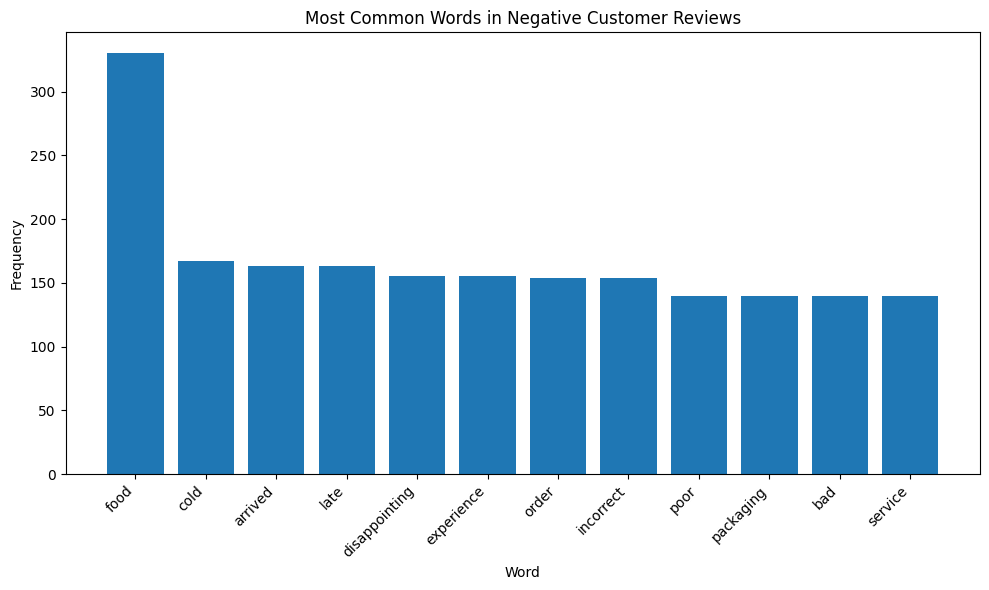

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    top_complaints["Word"],
    top_complaints["Frequency"]
)

plt.title("Most Common Words in Negative Customer Reviews")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "top_customer_complaint_words.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
import pandas as pd

complaint_categories = {
    "Late Delivery": [
        "late", "delay", "slow", "waiting", "time"
    ],
    "Incorrect or Missing Order": [
        "incorrect", "wrong", "missing", "item", "order"
    ],
    "Food Quality": [
        "cold", "stale", "taste", "quality", "fresh", "undercooked"
    ],
    "Packaging Issues": [
        "packaging", "package", "spill", "leak", "damaged"
    ],
    "Customer Service": [
        "service", "rude", "support", "staff", "response"
    ],
    "High Prices": [
        "expensive", "price", "cost", "overpriced"
    ]
}

negative_reviews = reviews_cleaned[
    reviews_cleaned["sentiment"] == "Negative"
].copy()

def identify_complaints(review):
    review = str(review).lower()

    matched_categories = [
        category
        for category, keywords in complaint_categories.items()
        if any(keyword in review.split() for keyword in keywords)
    ]

    return ", ".join(matched_categories) if matched_categories else "Other"

negative_reviews["complaint_category"] = (
    negative_reviews["processed_review"].apply(identify_complaints)
)

display(
    negative_reviews[
        ["review_text", "complaint_category"]
    ].head(15)
)

,review_text,complaint_category
3,Order was incorrect,Incorrect or Missing Order
4,Poor packaging and bad service,"Packaging Issues, Customer Service"
7,Order was incorrect,Incorrect or Missing Order
12,Food was cold,Food Quality
13,Food arrived late,Late Delivery
17,Order was incorrect,Incorrect or Missing Order
18,Order was incorrect,Incorrect or Missing Order
28,Poor packaging and bad service,"Packaging Issues, Customer Service"
31,Food arrived late,Late Delivery
34,Poor packaging and bad service,"Packaging Issues, Customer Service"


In [22]:
category_counts = (
    negative_reviews["complaint_category"]
    .str.split(", ")
    .explode()
    .value_counts()
    .reset_index()
)

category_counts.columns = ["Complaint Category", "Review Count"]

display(category_counts)

,Complaint Category,Review Count
0,Food Quality,167
1,Late Delivery,163
2,Other,155
3,Incorrect or Missing Order,154
4,Packaging Issues,140
5,Customer Service,140


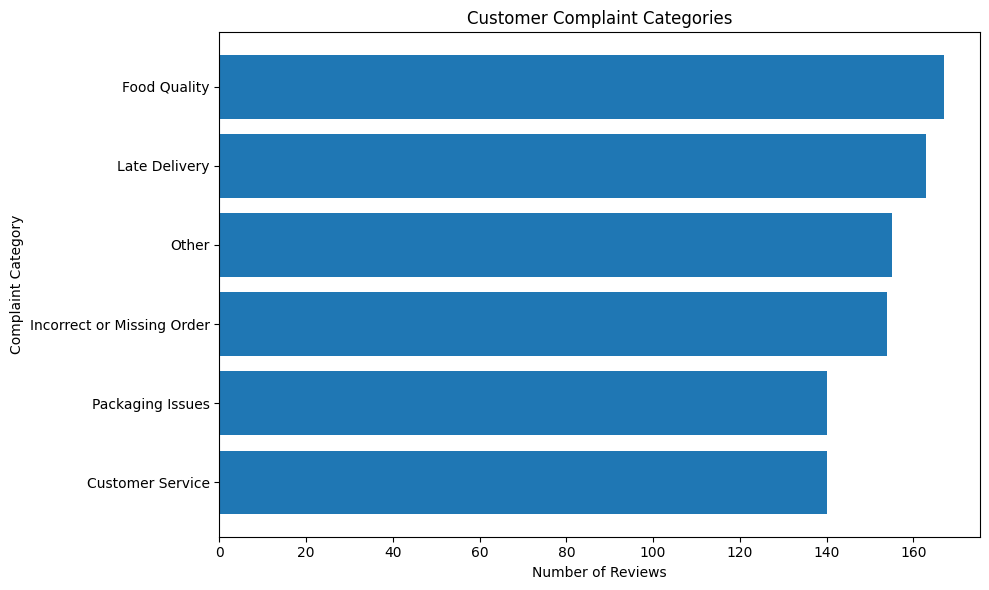

In [23]:
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(10, 6))

plt.barh(
    category_counts["Complaint Category"],
    category_counts["Review Count"]
)

plt.title("Customer Complaint Categories")
plt.xlabel("Number of Reviews")
plt.ylabel("Complaint Category")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "customer_complaint_categories.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
# Sentiment counts and percentages
sentiment_summary = (
    reviews_cleaned["sentiment"]
    .value_counts()
    .rename_axis("Sentiment")
    .reset_index(name="Review Count")
)

sentiment_summary["Percentage"] = (
    sentiment_summary["Review Count"]
    / len(reviews_cleaned)
    * 100
).round(2)

print("SENTIMENT SUMMARY")
display(sentiment_summary)

# Negative review percentage
negative_percentage = (
    (reviews_cleaned["sentiment"] == "Negative").mean() * 100
)

print(f"Negative reviews: {negative_percentage:.2f}%")

# Display the most frequent complaint categories
print("\nTOP COMPLAINT CATEGORIES")
display(category_counts.head(5))

SENTIMENT SUMMARY


,Sentiment,Review Count,Percentage
0,Positive,1766,58.87
1,Negative,779,25.97
2,Neutral,455,15.17


Negative reviews: 25.97%

TOP COMPLAINT CATEGORIES


,Complaint Category,Review Count
0,Food Quality,167
1,Late Delivery,163
2,Other,155
3,Incorrect or Missing Order,154
4,Packaging Issues,140


In [25]:
reviews_cleaned.to_csv(
    "../data/processed/reviews_with_sentiment_analysis.csv",
    index=False
)

print("Processed reviews saved successfully!")

Processed reviews saved successfully!


In [26]:
negative_reviews.to_csv(
    "../data/processed/categorized_customer_complaints.csv",
    index=False
)

category_counts.to_csv(
    "../data/processed/complaint_category_summary.csv",
    index=False
)

sentiment_summary.to_csv(
    "../data/processed/sentiment_summary.csv",
    index=False
)

print("Complaint analysis and sentiment summary saved successfully!")

Complaint analysis and sentiment summary saved successfully!


In [27]:
import joblib

joblib.dump(
    nb_model,
    "../data/processed/naive_bayes_sentiment_model.pkl"
)

joblib.dump(
    svm_model,
    "../data/processed/svm_sentiment_model.pkl"
)

print("Both trained models saved successfully!")

Both trained models saved successfully!
